# Supplementary — task sampling

Independent notebook for four-task insular coverage and subject/task counts.
Source: the approved Figure 1 sound Repeat cohort, frozen on 2026-10-17.
Anatomical sampling and confirmed responsiveness remain separate; incomplete
sound evidence is not a negative result. These figures reuse that cohort;
they do not redefine it using the ongoing native-data restoration.


In [2]:
from pathlib import Path
import sys, json, hashlib
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p/'.project-root').exists())
if str(ROOT) not in sys.path: sys.path.insert(0,str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from IPython.display import display
from matplotlib_inline.backend_inline import set_matplotlib_formats
get_ipython().run_line_magic('matplotlib','inline')
set_matplotlib_formats('svg')
from src.main_analysis import TASKS, COHORT_DIR, CONDITION, MODALITY, ROI_COLORS
for path in (Path(sys.prefix)/'fonts').glob('arial*.ttf'):
    font_manager.fontManager.addfont(str(path))
plt.rcParams.update({'svg.fonttype':'none','font.family':'sans-serif',
                     'font.sans-serif':['Arial'],'font.size':7,
                     'axes.linewidth':.75,'xtick.labelsize':7,'ytick.labelsize':7})
cm=1/2.54
TOPIC='task_sampling'
DATA_DIR=ROOT/'results/supplementary'/TOPIC
IMG_DIR=ROOT/'img/supplementary'/TOPIC
DATA_DIR.mkdir(parents=True,exist_ok=True); IMG_DIR.mkdir(parents=True,exist_ok=True)
from src.main_analysis import TASK_DISPLAY_NAMES
TASK_LABELS=TASK_DISPLAY_NAMES.copy()
def save(fig,name,tight=True):
    target=IMG_DIR/name
    fig.savefig(target,bbox_inches='tight' if tight else None,dpi=300)
    plt.show();plt.close(fig)
    return target


In [3]:
sample=pd.read_csv(COHORT_DIR/'sampled_sites_by_subject_task.csv')
unique=pd.read_csv(COHORT_DIR/'sampled_sites_unique.csv')
summary=pd.read_csv(COHORT_DIR/'task_summary.csv')
reference=pd.read_csv(ROOT/'results/fig1/insula_plot_coordinates.csv')
cohort_info=json.loads((COHORT_DIR/'summary.json').read_text())
assert not sample.duplicated(['subject','task','site_id']).any()
assert set(sample.task)==set(TASKS)
assert set(sample.site_id)==set(unique.site_id)==set(reference.channel)
assert sample.site_id.nunique()==cohort_info['sampled_sites']==348
assert unique.loc[unique.confirmed_responsive,'site_id'].nunique()==cohort_info['responsive_sites']==231
task_counts=summary.set_index('task').loc[list(TASKS)].copy()
for task in TASKS:
    frame=sample.loc[sample.task.eq(task)]
    assert len(frame)==task_counts.loc[task,'n_sampled_bipolar_sites']
    assert int(frame.confirmed_responsive.sum())==task_counts.loc[task,'n_confirmed_responsive_bipolar_sites']
    assert frame.subject.nunique()==task_counts.loc[task,'n_subjects_with_sampled_sites']
subject_counts=(sample.groupby(['subject','task'])
    .agg(n_sampled=('site_id','nunique'),n_confirmed_responsive=('confirmed_responsive','sum'),
         n_incomplete=('response_evidence_status',lambda x:int(x.eq('incomplete').sum())))
    .reindex(pd.MultiIndex.from_product([sorted(sample.subject.unique()),list(TASKS)],
                                       names=['subject','task']),fill_value=0).reset_index())
sample.to_csv(DATA_DIR/'sampled_sites_by_subject_task.csv',index=False)
subject_counts.to_csv(DATA_DIR/'subject_task_counts.csv',index=False)
task_counts.reset_index().to_csv(DATA_DIR/'task_counts.csv',index=False)
reference.to_csv(DATA_DIR/'frozen_display_coordinates.csv',index=False)
display(task_counts[['n_subjects_with_sampled_sites','n_sampled_bipolar_sites',
                     'n_subjects_with_responsive_sites','n_confirmed_responsive_bipolar_sites']])


,n_subjects_with_sampled_sites,n_sampled_bipolar_sites,n_subjects_with_responsive_sites,n_confirmed_responsive_bipolar_sites
task,,,,
PhonemeSequence,36,173,32,104
LexicalDelay,38,214,37,126
PictureNaming,28,162,26,91
SentenceRep,16,56,14,28


## Task totals


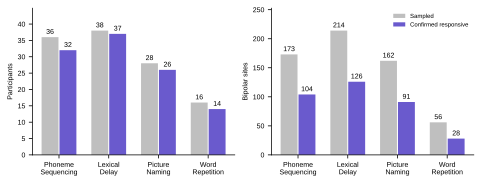

PosixPath('/cwork/ns458/insula-paper/img/supplementary/task_sampling/supp_task_counts.svg')

In [4]:
fig,axes=plt.subplots(1,2,figsize=(17*cm,6.5*cm))
x=np.arange(len(TASKS));color=ROI_COLORS['Insula']
for ax,allcol,rescol,ylabel in [
    (axes[0],'n_subjects_with_sampled_sites','n_subjects_with_responsive_sites','Participants'),
    (axes[1],'n_sampled_bipolar_sites','n_confirmed_responsive_bipolar_sites','Bipolar sites')]:
    sampled=task_counts[allcol].to_numpy(); responsive=task_counts[rescol].to_numpy()
    ax.bar(x-.18,sampled,.34,color='0.75',label='Sampled')
    ax.bar(x+.18,responsive,.34,color=color,label='Confirmed responsive')
    for xx,yy in zip(x-.18,sampled):ax.text(xx,yy+max(sampled)*.015,str(int(yy)),ha='center',va='bottom',fontsize=7)
    for xx,yy in zip(x+.18,responsive):ax.text(xx,yy+max(sampled)*.015,str(int(yy)),ha='center',va='bottom',fontsize=7)
    ax.set_xticks(x,[TASK_LABELS[t].replace(' ','\n',1) for t in TASKS]);ax.set_ylabel(ylabel)
    ax.set_ylim(0,max(sampled)*1.18);ax.spines[['top','right']].set_visible(False)
axes[1].legend(frameon=False,fontsize=6,loc='upper right')
fig.tight_layout();save(fig,'supp_task_counts.svg')


## Anatomical coverage by task

Reuse Figure 1's exact display coordinates, template, camera, insula mesh
and gyrus contour helpers. The helper source is copied into this independent
notebook at creation; the main notebook is never executed. Responsiveness
is task-specific here, rather than the across-task response union.


In [5]:
import os, subprocess, time
import mne,pyvista as pv
from mne.viz import Brain
from scipy.spatial import cKDTree

def _ensure_offscreen_display():
    """This node has no X display. Match the Figure 1 Slurm wrapper: Xvfb plus the MNE notebook backend."""
    if not os.environ.get('DISPLAY'):
        started=False
        for n in range(99,200):
            if os.path.exists(f'/tmp/.X{n}-lock'):
                continue
            display=f':{n}'
            proc=subprocess.Popen(
                ['Xvfb',display,'-screen','0','1600x1600x24','-nolisten','tcp'],
                stdout=subprocess.DEVNULL,stderr=subprocess.DEVNULL)
            for _ in range(40):
                if os.path.exists(f'/tmp/.X{n}-lock'):
                    os.environ['DISPLAY']=display
                    started=True
                    break
                if proc.poll() is not None:
                    break
                time.sleep(0.05)
            if started:
                break
        if not os.environ.get('DISPLAY'):
            raise RuntimeError('Xvfb did not start; MNE Brain needs a display on this node')
    os.environ['PYVISTA_OFF_SCREEN']='true'
    os.environ['PYVISTA_USE_PANEL']='false'
    os.environ['MNE_3D_BACKEND']='notebook'
    pv.OFF_SCREEN=True
    mne.viz.set_3d_backend('notebook')

_ensure_offscreen_display()
SOURCE_ROOT=Path('/hpc/group/coganlab/nanlinshi/insula-functional')
recon_dir='/cwork/ns458/ECoG_Recon/'
coords_unique=reference.copy()
coords_unique['is_insula']=True
responsive_site_ids=set(unique.loc[unique.confirmed_responsive,'site_id'])
fontsize=7


Using notebook 3d backend.


In [6]:
# Hammers MNI152 insula highlight on cvs_avg35_inMNI152 pial surface.
# Pial vertices and electrode x/y/z are CVS tkRAS; Hammers maxprob volume is MNI152 RAS.
import re
import nibabel as nib
from mne import Label

FS_SUBJECT = 'cvs_avg35_inMNI152'
HAMMERS_MAXPROB_NAME = 'Hammers-n30r95-maxprob-full-MNI152.nii.gz'
HAMMERS_MNI152_CANDIDATES = [
    SOURCE_ROOT / 'tmp/atlases' / HAMMERS_MAXPROB_NAME,
    Path(
        '/cwork/ns458/atlases/Hammersmith_n30r95/derivatives/faillenot_spm_mni152'
        '/probability_maps'
    ) / HAMMERS_MAXPROB_NAME,
    DATA_DIR / 'atlas_cache' / HAMMERS_MAXPROB_NAME,
]
HAMMERS_MAXPROB_TAR = Path(
    '/cwork/ns458/atlases/Hammersmith_n30r95/raw/Hammers-n30r95-maxprob-MNI152.tar'
)


def resolve_hammers_mni152():
    """Cwork probability_maps is empty; extract maxprob from the source tar if needed."""
    for path in HAMMERS_MNI152_CANDIDATES:
        if path.exists():
            return str(path)
    dest = HAMMERS_MNI152_CANDIDATES[-1]
    dest.parent.mkdir(parents=True, exist_ok=True)
    import tarfile
    with tarfile.open(HAMMERS_MAXPROB_TAR) as tf:
        src = tf.extractfile(HAMMERS_MAXPROB_NAME)
        if src is None:
            raise FileNotFoundError(
                f'{HAMMERS_MAXPROB_NAME} missing from {HAMMERS_MAXPROB_TAR}'
            )
        dest.write_bytes(src.read())
    return str(dest)


HAMMERS_MNI152_PATH = resolve_hammers_mni152()
# Full Hammers insula = six gyri (bilateral). Same as slice_render.MAPER_INSULA_IDS.
HAMMERS_INSULA_INDEX = {
    20: 'posterior long gyrus',
    21: 'posterior long gyrus',
    86: 'anterior short gyrus',
    87: 'anterior short gyrus',
    88: 'middle short gyrus',
    89: 'middle short gyrus',
    90: 'posterior short gyrus',
    91: 'posterior short gyrus',
    92: 'anterior pole',
    93: 'anterior pole',
    94: 'anterior long gyrus',
    95: 'anterior long gyrus',
}
HAMMERS_INSULA_IDS = frozenset(HAMMERS_INSULA_INDEX)
# Packaged roi crosswalk (docs/PARCELLATION_PIPELINE.md).
HAMMERS_AIC_IDS = frozenset({86, 87, 88, 89, 90, 91, 92, 93})
HAMMERS_PIC_IDS = frozenset({94, 95, 20, 21})
HAMMERS_GYRUS_TO_IDS = {
    'anterior short gyrus': frozenset({86, 87}),
    'middle short gyrus': frozenset({88, 89}),
    'posterior short gyrus': frozenset({90, 91}),
    'anterior pole': frozenset({92, 93}),
    'anterior long gyrus': frozenset({94, 95}),
    'posterior long gyrus': frozenset({20, 21}),
}
PANEL_A_INSULA_HIGHLIGHT_RADIUS_MM = 2.0


def _cvs_tkr_to_mni_ras(recon_dir, subject=FS_SUBJECT):
    """CVS-average pial tkRAS → MNI152 scanner RAS."""
    cvs_orig = nib.load(f'{recon_dir}/{subject}/mri/orig.mgz')
    mni_to_cvs_tkr = (
        cvs_orig.header.get_vox2ras_tkr()
        @ np.linalg.inv(cvs_orig.affine)
    )
    return np.linalg.inv(mni_to_cvs_tkr)


def _sample_hammers_labels(surface_coords, atlas_data, atlas_inv, *, cvs_tkr_to_mni):
    mni_coords = nib.affines.apply_affine(cvs_tkr_to_mni, surface_coords)
    ijk = nib.affines.apply_affine(atlas_inv, mni_coords).round().astype(int)
    out = np.zeros(len(surface_coords), dtype=int)
    shape = atlas_data.shape
    valid = (
        (ijk[:, 0] >= 0) & (ijk[:, 0] < shape[0])
        & (ijk[:, 1] >= 0) & (ijk[:, 1] < shape[1])
        & (ijk[:, 2] >= 0) & (ijk[:, 2] < shape[2])
    )
    if valid.any():
        v = ijk[valid]
        out[valid] = atlas_data[v[:, 0], v[:, 1], v[:, 2]].astype(int)
    return out


def _hemi_from_x(x):
    return 'lh' if x < 0 else 'rh'


def _parse_hammers_gyrus(label):
    if pd.isna(label):
        return None
    text = str(label).strip()
    if not text or text == '0':
        return None
    match = re.search(r'insula\s+(.+?)\s+[LR]$', text, flags=re.I)
    return match.group(1).strip().lower() if match else None


def _insula_vertex_ids_for_ids(vtx_ids, hemi, atlas_ids):
    vertices = set()
    for atlas_idx in atlas_ids:
        expected_hemi = 'lh' if atlas_idx % 2 == 0 else 'rh'
        if expected_hemi != hemi:
            continue
        vertices.update(np.where(vtx_ids == atlas_idx)[0].tolist())
    return vertices


def _vertices_near_points(pial_coords, anchor_points, radius_mm):
    if len(anchor_points) == 0:
        return set()
    dists = np.linalg.norm(pial_coords[:, None, :] - anchor_points[None, :, :], axis=2)
    return set(np.where(dists.min(axis=1) <= radius_mm)[0].tolist())


def load_hammers_insula_highlight_labels(
    insula_electrodes,
    *,
    recon_dir=recon_dir,
    subject=FS_SUBJECT,
    atlas_path=HAMMERS_MNI152_PATH,
    highlight_radius_mm=PANEL_A_INSULA_HIGHLIGHT_RADIUS_MM,
):
    """Merged per-hemisphere Hammers AIC+PIC highlight for Panel A."""
    img = nib.load(atlas_path)
    atlas_data = np.asarray(img.dataobj).squeeze()
    atlas_inv = np.linalg.inv(img.affine)
    cvs_tkr_to_mni = _cvs_tkr_to_mni_ras(recon_dir, subject=subject)

    pial_by_hemi = {}
    vtx_ids_by_hemi = {}
    for hemi in ('lh', 'rh'):
        coords, _ = mne.read_surface(f'{recon_dir}/{subject}/surf/{hemi}.pial')
        pial_by_hemi[hemi] = coords
        vtx_ids_by_hemi[hemi] = _sample_hammers_labels(
            coords, atlas_data, atlas_inv, cvs_tkr_to_mni=cvs_tkr_to_mni,
        )

    labels = []
    for hemi in ('lh', 'rh'):
        vertices = _insula_vertex_ids_for_ids(
            vtx_ids_by_hemi[hemi], hemi, HAMMERS_INSULA_IDS,
        )

        hemi_elec = insula_electrodes.loc[
            insula_electrodes['x'].map(_hemi_from_x) == hemi,
            ['x', 'y', 'z', 'label'],
        ]
        if not hemi_elec.empty:
            pial_coords = pial_by_hemi[hemi]
            tree = cKDTree(pial_coords)
            elec_xyz = hemi_elec[['x', 'y', 'z']].values
            _, proj_idx = tree.query(elec_xyz)
            proj_points = pial_coords[proj_idx]
            vertices.update(
                _vertices_near_points(
                    pial_coords, proj_points, highlight_radius_mm,
                )
            )

        if not vertices:
            continue
        side = 'L' if hemi == 'lh' else 'R'
        labels.append(Label(
            vertices=sorted(vertices),
            hemi=hemi,
            name=f'Hammers insula {side}',
            subject=subject,
        ))
    return labels


insula_electrodes_for_highlight = coords_unique.loc[coords_unique['is_insula']].copy()
hammers_insula_highlight_labels = load_hammers_insula_highlight_labels(
    insula_electrodes_for_highlight,
)
print(
    'Hammers insula highlight:',
    {lab.hemi: len(lab.vertices) for lab in hammers_insula_highlight_labels},
)


Hammers insula highlight: {'lh': 2622, 'rh': 2567}


In [7]:
# Panel B helpers — insula-only mesh on cvs_avg35_inMNI152 pial (same as fig2)
from matplotlib.lines import Line2D
from scipy.spatial import cKDTree

lh_pial_coords, lh_faces = mne.read_surface(
    f'{recon_dir}/{FS_SUBJECT}/surf/lh.pial'
)
rh_pial_coords, rh_faces = mne.read_surface(
    f'{recon_dir}/{FS_SUBJECT}/surf/rh.pial'
)
INSULA_MESH_COLOR = (0.9, 0.9, 0.9)
INSULA_MESH_ALPHA = 0.55
ELECTRODE_OFFSET_MM = 4.0
HAMMERS_FILL_MAX_MM = 8.0
POINT_SIZE_NSIG = 7
POINT_SIZE_SIG = 12
NSIG_COLOR = 'gray'

HAMMERS_GYRI = [
    'anterior pole',
    'anterior short gyrus',
    'middle short gyrus',
    'anterior long gyrus',
    'posterior short gyrus',
    'posterior long gyrus',
]
INSULA_PATTERNS = [
    'G_insular_short', 'G_Ins_lg_and_S_cent_ins',
    'S_circular_insula_ant', 'S_circular_insula_inf', 'S_circular_insula_sup',
]

labels = mne.read_labels_from_annot(
    subject=FS_SUBJECT, parc='aparc.a2009s',
    surf_name='pial', hemi='both', subjects_dir=recon_dir,
)


def _insula_vertices(hemi):
    verts = []
    for lab in labels:
        if lab.hemi == hemi and any(p in lab.name for p in INSULA_PATTERNS):
            verts.extend(lab.vertices)
    if not verts:
        raise RuntimeError(f'No insula labels for {hemi}')
    return np.unique(verts)


def _faces_to_polydata(coords, faces):
    faces_pv = np.hstack(
        [
            np.full((len(faces), 1), 3, dtype=np.int64),
            np.asarray(faces, dtype=np.int64),
        ]
    ).ravel()
    return pv.PolyData(np.asarray(coords, dtype=float), faces_pv)


def _insula_outward_normals(pial, faces, verts):
    """Area-weighted normals on insula vertices, flipped away from the centroid."""
    verts = np.asarray(verts)
    keep = np.all(np.isin(faces, verts), axis=1)
    ins_faces = np.asarray(faces[keep], dtype=np.int64)
    normals = np.zeros_like(pial, dtype=float)
    v0 = pial[ins_faces[:, 0]]
    v1 = pial[ins_faces[:, 1]]
    v2 = pial[ins_faces[:, 2]]
    face_n = np.cross(v1 - v0, v2 - v0)
    np.add.at(normals, ins_faces[:, 0], face_n)
    np.add.at(normals, ins_faces[:, 1], face_n)
    np.add.at(normals, ins_faces[:, 2], face_n)
    nrm = normals[verts]
    lengths = np.linalg.norm(nrm, axis=1, keepdims=True)
    valid = lengths[:, 0] > 1e-12
    nrm[valid] /= lengths[valid]
    centered = pial[verts] - pial[verts].mean(axis=0)
    nrm[np.einsum('ij,ij->i', nrm, centered) < 0] *= -1
    out = np.zeros_like(pial, dtype=float)
    out[verts] = nrm
    return out


def _prepare_insula_surface(hemi, pial, faces):
    """Insula mesh and per-vertex outward normals for later camera-facing snap."""
    verts = _insula_vertices(hemi)
    keep = np.all(np.isin(faces, verts), axis=1)
    ins_faces = np.asarray(faces[keep], dtype=np.int64)
    return {
        'mesh': _faces_to_polydata(pial, ins_faces),
        'faces': ins_faces,
        'center': pial[verts].mean(axis=0),
        'verts': verts,
        'normals': _insula_outward_normals(pial, faces, verts),
    }


lh_surf = _prepare_insula_surface('lh', lh_pial_coords, lh_faces)
rh_surf = _prepare_insula_surface('rh', rh_pial_coords, rh_faces)
lh_insula, lh_insula_center = lh_surf['mesh'], lh_surf['center']
rh_insula, rh_insula_center = rh_surf['mesh'], rh_surf['center']


def _hide_default_pial(brain):
    """Alpha=0 pial still writes the depth buffer and buries contacts."""
    collection = brain._renderer.plotter.renderer.GetActors()
    collection.InitTraversal()
    for _ in range(collection.GetNumberOfItems()):
        collection.GetNextActor().SetVisibility(False)


def _make_insula_brain(hemi):
    """Whole-hemisphere cortex hidden; only aparc.a2009s insula faces."""
    brain = Brain(
        FS_SUBJECT, subjects_dir=recon_dir, surf='pial',
        hemi=hemi, background='white', show=False,
        cortex=INSULA_MESH_COLOR, alpha=0.0, size=(800, 800),
    )
    _hide_default_pial(brain)
    mesh = lh_insula if hemi == 'lh' else rh_insula
    brain._renderer.plotter.add_mesh(
        mesh,
        color=INSULA_MESH_COLOR,
        opacity=INSULA_MESH_ALPHA,
        lighting=True,
        smooth_shading=True,
    )
    return brain


insula_electrodes = coords_unique.loc[coords_unique['is_insula']].copy()
insula_electrodes['is_significant'] = insula_electrodes['channel'].isin(
    responsive_site_ids
)
n_sig = int(insula_electrodes['is_significant'].sum())
print(
    f'Insula electrodes for Panel B: {len(insula_electrodes)} sampled, '
    f'{n_sig} significant (Repeat, any of stimulus/delay/response)'
)


def _camera_xyz(brain):
    cam = brain._renderer.plotter.camera
    pos = cam.GetPosition() if hasattr(cam, 'GetPosition') else cam.position
    return np.asarray(pos, dtype=float)


def _project_to_insula(cord, surf, pial, camera_pos):
    """Snap to camera-facing insula vertices and lift toward the camera."""
    cam = np.asarray(camera_pos, dtype=float).reshape(1, 3)
    verts = surf['verts']
    xyz = pial[verts]
    nrm = surf['normals'][verts]
    to_cam = cam - xyz
    to_cam /= np.clip(np.linalg.norm(to_cam, axis=1, keepdims=True), 1e-6, None)
    facing = np.einsum('ij,ij->i', nrm, to_cam) > 0.0
    if int(facing.sum()) < 50:
        facing = np.ones(len(verts), dtype=bool)
    vis = verts[facing]
    _, idx = cKDTree(pial[vis]).query(cord)
    pts = pial[vis[idx]]
    lift = cam - pts
    lift /= np.clip(np.linalg.norm(lift, axis=1, keepdims=True), 1e-6, None)
    return pts + ELECTRODE_OFFSET_MM * lift


def _add_electrodes_fixed(brain, coords_proj, colors, point_sizes):
    for i, pt in enumerate(coords_proj):
        color = colors[i]
        if color is None or (isinstance(color, float) and np.isnan(color)):
            continue
        cloud = pv.PolyData(pt.reshape(1, 3))
        actor = brain._renderer.plotter.add_mesh(
            cloud, render_points_as_spheres=True,
            point_size=float(point_sizes[i]), color=color, lighting=False,
        )
        mapper = getattr(actor, 'mapper', None)
        if mapper is None and hasattr(actor, 'GetMapper'):
            mapper = actor.GetMapper()
        if mapper is not None and hasattr(
            mapper, 'SetResolveCoincidentTopologyToPolygonOffset'
        ):
            mapper.SetResolveCoincidentTopologyToPolygonOffset()


def _points_to_pixels(plotter, points, image_shape):
    pts = np.asarray(points, dtype=float)
    if pts.size == 0:
        return np.zeros((0, 2), dtype=float)
    if pts.ndim == 1:
        pts = pts.reshape(1, 3)
    if hasattr(plotter, 'project_points_to_pixels'):
        pix = np.asarray(plotter.project_points_to_pixels(pts), dtype=float)
        xy = np.asarray(pix[:, :2], dtype=float)
    else:
        import vtk

        renderer = plotter.renderer
        coordinate = vtk.vtkCoordinate()
        coordinate.SetCoordinateSystemToWorld()
        xy = np.zeros((len(pts), 2), dtype=float)
        for i, (x, y, z) in enumerate(pts):
            coordinate.SetValue(float(x), float(y), float(z))
            d = coordinate.GetComputedDisplayValue(renderer)
            xy[i] = (float(d[0]), float(d[1]))
    xy[:, 1] = (int(image_shape[0]) - 1) - xy[:, 1]
    return xy


def _hammers_gyrus_code(names):
    code = np.zeros(len(names), dtype=np.int8)
    for idx, gyrus in enumerate(HAMMERS_GYRI, start=1):
        code[names == gyrus] = idx
    return code


def _xy_arclength(xy):
    xy = np.asarray(xy, dtype=float)
    if len(xy) < 2:
        return 0.0
    return float(np.linalg.norm(np.diff(xy, axis=0), axis=1).sum())


def _pial_hammers_gyrus(pial, hemi):
    """Paint Destrieux insula verts by Hammers gyrus, filling pial/CSF holes."""
    img = nib.load(HAMMERS_MNI152_PATH)
    atlas_data = np.asarray(img.dataobj).squeeze()
    atlas_inv = np.linalg.inv(img.affine)
    cvs = _cvs_tkr_to_mni_ras(recon_dir, subject=FS_SUBJECT)
    ids = _sample_hammers_labels(
        pial, atlas_data, atlas_inv, cvs_tkr_to_mni=cvs,
    )
    hemi_ids = [
        atlas_idx for atlas_idx in HAMMERS_INSULA_IDS
        if ('lh' if atlas_idx % 2 == 0 else 'rh') == hemi
    ]
    verts = _insula_vertices(hemi)
    miss = ~np.isin(ids[verts], hemi_ids)
    if miss.any():
        mask = np.isin(atlas_data, hemi_ids)
        ijk = np.column_stack(np.where(mask))
        xyz = nib.affines.apply_affine(img.affine, ijk)
        mni_miss = nib.affines.apply_affine(cvs, pial[verts[miss]])
        dist, nn = cKDTree(xyz).query(mni_miss)
        filled = atlas_data[ijk[nn, 0], ijk[nn, 1], ijk[nn, 2]].astype(int)
        filled[dist > HAMMERS_FILL_MAX_MM] = 0
        ids[verts[miss]] = filled
    return np.array(
        [HAMMERS_INSULA_INDEX.get(int(i), '') for i in ids], dtype=object,
    )


def _render_insula_hemi(hemi, cord, colors, point_sizes):
    surf = lh_surf if hemi == 'lh' else rh_surf
    pial = lh_pial_coords if hemi == 'lh' else rh_pial_coords
    center = lh_insula_center if hemi == 'lh' else rh_insula_center
    azimuth = 180 if hemi == 'lh' else 0
    brain = _make_insula_brain(hemi)
    brain.show_view(
        azimuth=azimuth, elevation=90, distance=180, focalpoint=center,
    )
    if cord is not None and len(cord):
        proj = _project_to_insula(cord, surf, pial, _camera_xyz(brain))
        _add_electrodes_fixed(brain, proj, colors, point_sizes)
    plotter = brain._renderer.plotter
    for _ in range(2):
        plotter.render()
    img = np.asarray(brain.screenshot(mode='rgb'))

    def project(points):
        return _points_to_pixels(plotter, points, img.shape[:2])

    return img, project, brain


def plot_insula_electrode_panel(
    plot_df,
    *,
    colors,
    title,
    legend_handles=None,
    save_path=None,
    overlay_collect=None,
    point_sizes=None,
):
    """L/R insula-only pial with electrodes projected onto the surface."""
    if plot_df.empty:
        print(f'Skip plot (no electrodes): {title}')
        return

    cord = plot_df[['x', 'y', 'z']].values
    colors = np.asarray(colors, dtype=object)
    if point_sizes is None:
        point_sizes = np.full(len(plot_df), POINT_SIZE_SIG, dtype=float)
    else:
        point_sizes = np.asarray(point_sizes, dtype=float)
    mask_lh = cord[:, 0] < 0
    mask_rh = cord[:, 0] > 0
    rendered = {}
    for hemi, mask in (('lh', mask_lh), ('rh', mask_rh)):
        xyz = cord[mask] if mask.any() else np.zeros((0, 3))
        col = colors[mask] if mask.any() else np.array([], dtype=object)
        sizes = point_sizes[mask] if mask.any() else np.array([], dtype=float)
        img, project, brain = _render_insula_hemi(hemi, xyz, col, sizes)
        overlay = overlay_collect(hemi, project) if overlay_collect else None
        brain.close()
        rendered[hemi] = (img, overlay)

    fig, axes = plt.subplots(1, 2, figsize=(16 * cm, 8 * cm))
    for ax, hemi, title_hemi in (
        (axes[0], 'lh', 'Left Insula'),
        (axes[1], 'rh', 'Right Insula'),
    ):
        img, overlay = rendered[hemi]
        ax.imshow(img)
        ax.axis('off')
        ax.set_title(title_hemi, fontsize=fontsize)
        if overlay:
            for xy in overlay.get('lines_minor', []):
                if len(xy) < 2:
                    continue
                ax.plot(
                    xy[:, 0], xy[:, 1],
                    linestyle=(0, (2.4, 1.8)), color='0.40', lw=0.65,
                    solid_capstyle='round', dash_capstyle='butt',
                    zorder=5,
                )

    if legend_handles:
        axes[0].legend(
            handles=legend_handles,
            loc='upper left', fontsize=fontsize - 1, framealpha=0.9,
        )

    plt.suptitle(f'{title} (n={len(plot_df)})', fontsize=fontsize)
    plt.tight_layout()

    if save_path:
        Path(save_path).parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(save_path, dpi=300, bbox_inches='tight')
        print(f'Saved {save_path}')

    plt.show()


lh_hammers_gyrus = _pial_hammers_gyrus(lh_pial_coords, 'lh')
rh_hammers_gyrus = _pial_hammers_gyrus(rh_pial_coords, 'rh')


Reading labels from parcellation...
   read 75 labels from /cwork/ns458/ECoG_Recon/cvs_avg35_inMNI152/label/lh.aparc.a2009s.annot
   read 75 labels from /cwork/ns458/ECoG_Recon/cvs_avg35_inMNI152/label/rh.aparc.a2009s.annot
Insula electrodes for Panel B: 348 sampled, 231 significant (Repeat, any of stimulus/delay/response)


In [8]:
# Fig B5 — sampled vs significant insula electrodes + gyrus boundaries
# Significant = Repeat mask=True in any of stimulus / delay / response windows.
from collections import defaultdict
from scipy.ndimage import gaussian_filter1d


def _trace_boundary_network(pial, faces, code):
    """Create continuous label contours through triangle-edge midpoints."""
    xyz_by_node = {}
    segments = set()

    def edge_node(i, j):
        i, j = sorted((int(i), int(j)))
        key = ('edge', i, j)
        xyz_by_node[key] = 0.5 * (pial[i] + pial[j])
        return key

    for face_idx, f in enumerate(faces):
        crossed = []
        for i, j in ((f[0], f[1]), (f[1], f[2]), (f[2], f[0])):
            a, b = int(code[i]), int(code[j])
            if a > 0 and b > 0 and a != b:
                crossed.append(edge_node(i, j))

        if len(crossed) == 2:
            segments.add(frozenset((crossed[0], crossed[1])))
        elif len(crossed) == 3:
            center = ('face', int(face_idx))
            xyz_by_node[center] = pial[np.asarray(f, dtype=int)].mean(axis=0)
            for node in crossed:
                segments.add(frozenset((node, center)))

    adjacency = defaultdict(set)
    for segment in segments:
        a, b = tuple(segment)
        adjacency[a].add(b)
        adjacency[b].add(a)

    visited = set()

    def walk(start, nxt):
        path = [start, nxt]
        visited.add(frozenset((start, nxt)))
        previous, current = start, nxt
        while len(adjacency[current]) == 2:
            candidates = [
                node for node in adjacency[current]
                if node != previous
                and frozenset((current, node)) not in visited
            ]
            if not candidates:
                break
            following = candidates[0]
            visited.add(frozenset((current, following)))
            path.append(following)
            previous, current = current, following
        return path

    paths = []
    for node, neighbors in adjacency.items():
        if len(neighbors) == 2:
            continue
        for neighbor in neighbors:
            if frozenset((node, neighbor)) not in visited:
                paths.append(walk(node, neighbor))

    for segment in segments:
        if segment in visited:
            continue
        a, b = tuple(segment)
        paths.append(walk(a, b))

    return [
        np.asarray([xyz_by_node[node] for node in path], dtype=float)
        for path in paths
    ]


def _smooth_boundary(xyz, spacing=0.4, sigma_mm=1.8):
    """Resample and gently smooth one contour without moving its endpoints."""
    step = np.linalg.norm(np.diff(xyz, axis=0), axis=1)
    keep = np.concatenate([[True], step > 1e-6])
    xyz = np.asarray(xyz, dtype=float)[keep]
    if len(xyz) < 3:
        return xyz

    distance = np.concatenate([
        [0.0], np.cumsum(np.linalg.norm(np.diff(xyz, axis=0), axis=1))
    ])
    if distance[-1] <= spacing:
        return xyz
    sample_at = np.linspace(
        0.0, distance[-1], max(8, int(np.ceil(distance[-1] / spacing)))
    )
    sampled = np.column_stack([
        np.interp(sample_at, distance, xyz[:, axis]) for axis in range(3)
    ])
    smoothed = np.column_stack([
        gaussian_filter1d(
            sampled[:, axis], sigma=sigma_mm / spacing, mode='nearest'
        )
        for axis in range(3)
    ])
    smoothed[0] = sampled[0]
    smoothed[-1] = sampled[-1]
    return smoothed


def overlay_continuous_gyrus_boundaries(hemi, project):
    pial = lh_pial_coords if hemi == 'lh' else rh_pial_coords
    surf = lh_surf if hemi == 'lh' else rh_surf
    names = lh_hammers_gyrus if hemi == 'lh' else rh_hammers_gyrus
    code = _hammers_gyrus_code(names)

    lines = []
    for xyz in _trace_boundary_network(pial, surf['faces'], code):
        if len(xyz) < 3:
            continue
        xy = project(_smooth_boundary(xyz))
        if _xy_arclength(xy) >= 8:
            lines.append(xy)

    return {'lines_minor': lines}


In [9]:
def _crop_panel(img, xy, overlay, pad=24):
    """Trim screenshot whitespace; shift scatter and overlays (same as fig2)."""
    rgb = np.asarray(img)
    mask = np.any(rgb < 250, axis=2)
    if not mask.any():
        return rgb, np.asarray(xy, dtype=float), overlay
    ys, xs = np.nonzero(mask)
    y0 = max(0, int(ys.min()) - pad)
    y1 = min(rgb.shape[0], int(ys.max()) + 1 + pad)
    x0 = max(0, int(xs.min()) - pad)
    x1 = min(rgb.shape[1], int(xs.max()) + 1 + pad)
    xy_c = np.asarray(xy, dtype=float).copy()
    if xy_c.size:
        xy_c[:, 0] -= x0
        xy_c[:, 1] -= y0
    overlay_c = {
        'lines_minor': [
            np.column_stack([line[:, 0] - x0, line[:, 1] - y0])
            for line in overlay.get('lines_minor', [])
        ],
    }
    return rgb[y0:y1, x0:x1], xy_c, overlay_c


phase,stimulus,delay,response
task,,,
PhonemeSequence,104,104,104
LexicalDelay,126,126,126
PictureNaming,91,91,91
SentenceRep,28,28,28


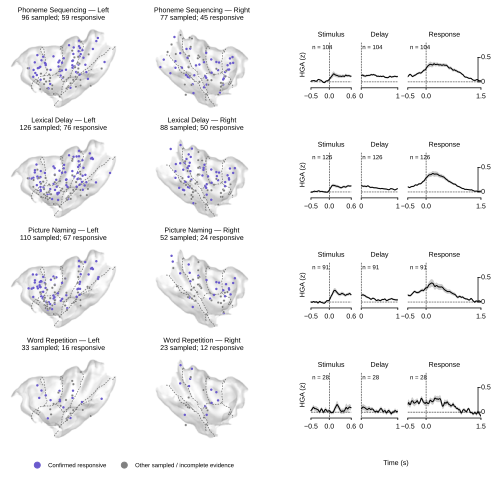

PosixPath('/cwork/ns458/insula-paper/img/supplementary/task_sampling/supp_task_insula_coverage.svg')

In [10]:
_ensure_offscreen_display()
backgrounds={};pixels=[]
for hemi in ['lh','rh']:
    side=reference.loc[reference.x.lt(0) if hemi=='lh' else reference.x.gt(0)].copy()
    image,project,brain=_render_insula_hemi(hemi,np.zeros((0,3)),np.array([],dtype=object),np.array([]))
    overlay=overlay_continuous_gyrus_boundaries(hemi,project)
    xy=project(side[['x','y','z']].to_numpy())
    brain.close()
    image,xy,overlay=_crop_panel(image,xy,overlay)
    side['pixel_x']=xy[:,0];side['pixel_y']=xy[:,1];side['display_hemi']=hemi
    pixels.append(side[['channel','pixel_x','pixel_y','display_hemi']])
    backgrounds[hemi]=(image,overlay)
pixel_table=pd.concat(pixels,ignore_index=True)
pixel_table.to_csv(DATA_DIR/'display_pixel_coordinates.csv',index=False)
import pickle
import re
import seaborn as sns

# Task-resolved Repeat + sound site waveforms. The pooled Figure 1 group trace
# is not used. Display windows match frozen fig1_insula_average_traces.svg.
TRACE_PHASES=['stimulus','delay','response']
TRACE_XLIMS={'stimulus':(-.5,.6),'delay':(0.,1.),'response':(-.5,1.5)}
TRACE_XTICKS={'stimulus':(-.5,0,.6),'delay':(0,1),'response':(-.5,0,1.5)}
TRACE_FONTSIZE=7
DATASET_ROOTS={
    'PhonemeSequence':Path('/cwork/ns458/BIDS-1.4_Phoneme_sequencing/BIDS'),
    'LexicalDelay':Path('/cwork/ns458/BIDS-1.0_LexicalDecRepDelay/BIDS'),
    'PictureNaming':Path('/cwork/ns458/BIDS-1.3_PictureNaming/BIDS'),
    'SentenceRep':Path('/cwork/ns458/BIDS-1.4_SentenceRep/BIDS'),
}
FIG1_STREAM=ROOT/'results/fig1/available_evidence_stream.pkl'
WAVE_CACHE=DATA_DIR/'task_responsive_hga_site_waveforms.csv.gz'
WAVE_COLUMNS=['subject','channel','task','phase','time','value']

def _epoch_site_rows(task_name,subject,phase,channels):
    """Same Repeat+sound high-gamma epochs and trial-mean as Figure 1."""
    import mne
    lo,hi=TRACE_XLIMS[phase]
    epoch_folder=DATASET_ROOTS[task_name]/'derivatives/epoch(bipolar)'/f'sub-{subject}'/'epoch(band)(zscore)'
    paths=sorted(epoch_folder.glob(f'*proc-{phase.capitalize()}_*desc-{CONDITION}_highgamma.h5')) if epoch_folder.is_dir() else []
    remaining=set(channels);frames=[];checked=[]
    for path in paths:
        checked.append(str(path))
        recording=re.search(r'_recording-([^_]+)',path.name)
        if (recording[1] if recording else 'sound')!=MODALITY:
            continue
        epochs=mne.read_epochs(path,preload=False,verbose='error')
        selected=sorted(remaining & set(epochs.ch_names))
        if not selected:
            continue
        epochs.load_data();epochs.pick(selected)
        evoked=epochs.average(method=lambda data: np.nanmean(data,axis=0))
        chosen=(evoked.times>=lo)&(evoked.times<=hi)
        rows=pd.DataFrame(evoked.data[:,chosen],index=evoked.ch_names,columns=evoked.times[chosen])
        rows=rows.rename_axis('channel').reset_index().melt(id_vars='channel',var_name='time',value_name='value')
        frames.append(rows.assign(subject=subject,task=task_name,phase=phase,modality=MODALITY))
        remaining-=set(selected)
        if not remaining:
            break
    if remaining:
        searched=checked or [str(epoch_folder)]
        raise FileNotFoundError(
            f'No Repeat+sound waveform for {sorted(remaining)} ({task_name}, {phase}). Checked: {searched}')
    return pd.concat(frames,ignore_index=True)

def _task_responsive_waveforms():
    if not FIG1_STREAM.is_file():
        raise FileNotFoundError(FIG1_STREAM)
    with FIG1_STREAM.open('rb') as handle:
        trace_rows=pickle.load(handle)['trace_rows']
    missing_cols={'task','channel','phase','modality','time','value'}-set(trace_rows.columns)
    if missing_cols:
        raise ValueError(f'{FIG1_STREAM} trace_rows missing {sorted(missing_cols)}')
    trace_rows=trace_rows.loc[trace_rows.modality.eq(MODALITY)].copy()
    trace_rows['subject']=trace_rows.channel.str.split('_').str[0]
    responsive=sample.loc[sample.confirmed_responsive.astype(bool),['subject','task','site_id']].rename(columns={'site_id':'channel'})
    trace_rows=trace_rows.merge(responsive,on=['subject','task','channel'],how='inner')
    keep=np.zeros(len(trace_rows),dtype=bool)
    for phase,(lo,hi) in TRACE_XLIMS.items():
        keep|=trace_rows.phase.eq(phase).to_numpy()&trace_rows.time.ge(lo).to_numpy()&trace_rows.time.le(hi).to_numpy()
    trace_rows=trace_rows.loc[keep]
    present=set(zip(trace_rows.task,trace_rows.channel,trace_rows.phase))
    supplements=[]
    for (task_name,subject),group in responsive.groupby(['task','subject']):
        for phase in TRACE_PHASES:
            missing=[channel for channel in group.channel if (task_name,channel,phase) not in present]
            if missing:
                supplements.append(_epoch_site_rows(task_name,subject,phase,missing))
    if supplements:
        trace_rows=pd.concat([trace_rows,*supplements],ignore_index=True)
    trace_rows=trace_rows.loc[np.isfinite(trace_rows.value)]
    trace_rows['time']=(trace_rows['time'].astype(float)*128).round()/128
    # One waveform per site. Duplicate exports are averaged; sites are not averaged within a participant.
    site_level=trace_rows.groupby(['subject','channel','task','phase','time'],as_index=False).value.mean()
    kept=[]
    for (task_name,phase),frame in site_level.groupby(['task','phase']):
        n_sites=frame.channel.nunique()
        counts=frame.groupby('time').channel.nunique()
        shared=set(counts.index[counts.eq(n_sites)])
        if n_sites and not shared:
            raise AssertionError(f'No shared time grid for {task_name} {phase}')
        kept.append(frame.loc[frame.time.isin(shared)])
    site_waves=pd.concat(kept,ignore_index=True)[WAVE_COLUMNS]
    site_waves.to_csv(WAVE_CACHE,index=False)
    return site_waves

if WAVE_CACHE.is_file():
    site_waves=pd.read_csv(WAVE_CACHE)
    if not set(WAVE_COLUMNS).issubset(site_waves.columns):
        site_waves=_task_responsive_waveforms()
else:
    site_waves=_task_responsive_waveforms()
site_waves=site_waves.loc[site_waves.task.isin(TASKS)&site_waves.phase.isin(TRACE_PHASES)].copy()
trace_counts=(site_waves.groupby(['task','phase']).channel.nunique()
              .unstack('phase').reindex(index=list(TASKS),columns=TRACE_PHASES))
display(trace_counts)

def _phase_mean(task,phase):
    frame=site_waves.loc[site_waves.task.eq(task)&site_waves.phase.eq(phase)]
    lo,hi=TRACE_XLIMS[phase]
    frame=frame.loc[frame.time.ge(lo)&frame.time.le(hi)]
    if frame.empty:
        return frame,0
    stats=frame.groupby('time').value.agg(['mean','std','count']).reset_index().sort_values('time')
    stats['sem']=stats['std']/np.sqrt(stats['count'])
    n_sites=int(frame.channel.nunique())
    if not stats['count'].eq(n_sites).all():
        raise AssertionError(f'{task} {phase} does not share one site count across time')
    return stats,n_sites

# Left brain, right brain, then a uniformly scaled Figure 1 trace block (8 cm x 3 cm).
fig_w_cm,fig_h_cm=18.0,16.0
brain_left_cm,brain_w_cm,gap_cm,trace_w_cm=0.10,9.70,0.22,7.70
trace_h_cm=trace_w_cm*(3.0/8.0)
top,bottom,hspace=0.98,0.062,0.28
row_h=(top-bottom)/(len(TASKS)+(len(TASKS)-1)*hspace)
row_gap=hspace*row_h
fig=plt.figure(figsize=(fig_w_cm*cm,fig_h_cm*cm))
brain_gs=fig.add_gridspec(
    len(TASKS),2,
    left=brain_left_cm/fig_w_cm,
    right=(brain_left_cm+brain_w_cm)/fig_w_cm,
    top=top,bottom=bottom,wspace=.02,hspace=hspace)
width_ratios=[hi-lo for lo,hi in (TRACE_XLIMS[phase] for phase in TRACE_PHASES)]
block_left=(brain_left_cm+brain_w_cm+gap_cm)/fig_w_cm
block_width=trace_w_cm/fig_w_cm
block_height=trace_h_cm/fig_h_cm
for i,task in enumerate(TASKS):
    task_sites=sample.loc[sample.task.eq(task)].merge(pixel_table,left_on='site_id',right_on='channel',validate='one_to_one')
    assert len(task_sites)==len(sample.loc[sample.task.eq(task)])
    for j,hemi in enumerate(['lh','rh']):
        ax=fig.add_subplot(brain_gs[i,j]);image,overlay=backgrounds[hemi]
        ax.imshow(image);ax.set_xlim(0,image.shape[1]);ax.set_ylim(image.shape[0],0);ax.axis('off')
        view=task_sites.loc[task_sites.display_hemi.eq(hemi)]
        for responsive,color in [(True,ROI_COLORS['Insula']),(False,'gray')]:
            points=view.loc[view.confirmed_responsive.eq(responsive)]
            ax.scatter(points.pixel_x,points.pixel_y,s=6,c=color,
                       edgecolors='none' if responsive else 'white',linewidths=.25,zorder=6 if responsive else 7)
        for line in overlay.get('lines_minor',[]):
            ax.plot(line[:,0],line[:,1],linestyle=(0,(2.4,1.8)),color='0.40',lw=.65,zorder=5)
        ax.set_title(f"{TASK_LABELS[task]} — {'Left' if hemi=='lh' else 'Right'}\n{len(view)} sampled; {int(view.confirmed_responsive.sum())} responsive",fontsize=7)
    row_bottom=top-(i+1)*row_h-i*row_gap
    pad=(row_h*fig_h_cm-trace_h_cm)/2/fig_h_cm
    block_bottom=row_bottom+pad
    trace_gs=fig.add_gridspec(
        1,len(TRACE_PHASES),
        left=block_left+0.16*block_width,
        right=block_left+0.94*block_width,
        bottom=block_bottom+0.28*block_height,
        top=block_bottom+0.82*block_height,
        wspace=0.2,width_ratios=width_ratios)
    trace_axes=[fig.add_subplot(trace_gs[0,j]) for j in range(len(TRACE_PHASES))]
    for ax,phase in zip(trace_axes,TRACE_PHASES):
        lo,hi=TRACE_XLIMS[phase]
        phase_df,n_sites=_phase_mean(task,phase)
        if n_sites:
            ax.plot(phase_df.time,phase_df['mean'],color='k',lw=1)
            ax.fill_between(phase_df.time,phase_df['mean']-phase_df['sem'],
                            phase_df['mean']+phase_df['sem'],color='k',alpha=.2,linewidth=0)
        ax.set_xlim(lo,hi)
        ax.set_xticks(TRACE_XTICKS[phase])
        ax.set_xlabel('')
        ax.set_title(phase.capitalize(),fontsize=TRACE_FONTSIZE)
        ax.text(0.03,0.95,f'n = {n_sites}',transform=ax.transAxes,ha='left',va='top',fontsize=6,color='k')
    for ax in trace_axes:
        ax.axvline(x=0,color='k',linestyle='--',linewidth=0.5,clip_on=False)
        ax.axhline(y=0,color='k',linestyle='--',linewidth=0.5,clip_on=False)
        ax.tick_params(labelsize=TRACE_FONTSIZE,width=0.75,length=2,which='both')
        plt.setp(ax.spines.values(),linewidth=0.75)
        sns.despine(ax=ax,offset=1,trim=True)
        ax.set_yticklabels([])
        ax.set_yticks([])
        ax.spines['left'].set_visible(False)
        ax.set_ylim(-0.1,0.8)
        ax.set_ylabel('HGA (z)' if ax is trace_axes[0] else '',fontsize=TRACE_FONTSIZE)
    scale=0.5
    ax=trace_axes[-1]
    xmin,xmax=ax.get_xlim()
    x_span=xmax-xmin
    x_bar=xmax-0.04*x_span
    cap=0.03*x_span
    ax.plot([x_bar,x_bar],[0.0,scale],color='k',lw=0.75,clip_on=False)
    ax.plot([x_bar,x_bar+cap],[0.0,0.0],color='k',lw=0.75,clip_on=False)
    ax.plot([x_bar,x_bar+cap],[scale,scale],color='k',lw=0.75,clip_on=False)
    ax.text(x_bar+1.4*cap,0.0,'0',fontsize=TRACE_FONTSIZE,va='center',ha='left')
    ax.text(x_bar+1.4*cap,scale,'0.5',fontsize=TRACE_FONTSIZE,va='center',ha='left')
handles=[Line2D([],[],marker='o',ls='',color=ROI_COLORS['Insula'],label='Confirmed responsive'),
         Line2D([],[],marker='o',ls='',color='gray',label='Other sampled / incomplete evidence')]
fig.legend(handles=handles,loc='upper center',
           bbox_to_anchor=((brain_left_cm+brain_w_cm/2)/fig_w_cm,0.028),
           ncol=2,frameon=False,fontsize=6)
fig.text(block_left+0.55*block_width,0.008,'Time (s)',ha='center',va='bottom',fontsize=TRACE_FONTSIZE)
save(fig,'supp_task_insula_coverage.svg')


## Four-task overlap — participants and sampled bipolar sites

One row of three area-scaled four-set Venn diagrams: all participants, all
recorded bipolar subject/site names, and the accepted sampled insula sites.
Use the same frozen Repeat + sound records and D0121 exclusion as Figure 1.
The participant set includes participants without accepted insula sites.

The full recorded-site panel precedes regional/anatomical response
filtering; it is not the curated ROI denominator or a significant-site set.
The insula panel uses the existing 348-site anatomical sampling list and
does not require significance. Whole-brain site intersections match Figure
1's recorded subject/site identifiers; native-coordinate conflicts remain
separately listed rather than being declared resolved by this diagram.

All 15 mutually exclusive intersections are labeled, including zeros.
Each number denotes membership in exactly the tasks covering that region.
Ellipse area is proportional to each task total. Exclusive counts stay
exact; overlap shapes are not proportional to those exclusive counts.
Detailed membership and inclusive/exclusive intersection tables accompany
the figure.


In [11]:
from src.supplementary.task_overlap import load_overlap_sets,draw_four_task_venn,draw_scaled_four_task_venn,SCOPES
venn_sets,venn_regions,venn_totals,venn_report=load_overlap_sets(ROOT,DATA_DIR)
venn_count_table=venn_totals.pivot(index='scope',columns='task',values='n_members').reindex(index=list(SCOPES),columns=list(TASKS))
venn_count_table['ALL_UNIQUE']=pd.Series(venn_report['unions'])
display(venn_count_table)
display(venn_regions)
print('Whole-brain sites use Figure 1 recorded names; native-coordinate-conflict names:',venn_report['native_coordinate_conflict_names'])
assert venn_report['unions']['insula_sites']==348
assert venn_report['significance_filter_applied'] is False


task,PhonemeSequence,LexicalDelay,PictureNaming,SentenceRep,ALL_UNIQUE
scope,,,,,
subjects,49,51,37,30,94
all_sites,8367,8446,6999,4171,15792
insula_sites,173,214,162,56,348


,scope,region,tasks,exclusive_count,inclusive_count
0,subjects,0001,SentenceRep,7,30
1,subjects,0010,PictureNaming,14,37
2,subjects,0011,PictureNaming|SentenceRep,0,3
3,subjects,0100,LexicalDelay,11,51
4,subjects,0101,LexicalDelay|SentenceRep,3,18
5,subjects,0110,LexicalDelay|PictureNaming,9,19
6,subjects,0111,LexicalDelay|PictureNaming|SentenceRep,1,3
7,subjects,1000,PhonemeSequence,13,49
8,subjects,1001,PhonemeSequence|SentenceRep,5,19
9,subjects,1010,PhonemeSequence|PictureNaming,4,13


Whole-brain sites use Figure 1 recorded names; native-coordinate-conflict names: 481


In [ ]:
fig_w_cm=18
left_cm,right_cm,gap_cm=0.12,0.12,0.22
top_cm,bottom_cm=0.88,0.70
fig,axes=plt.subplots(1,3,figsize=(fig_w_cm*cm,6*cm))
for ax,(scope,title) in zip(axes,SCOPES.items()):
    draw_scaled_four_task_venn(ax,venn_sets[scope],venn_regions.loc[venn_regions.scope.eq(scope)],title)
x0,x1=axes[0].get_xlim(); y0,y1=axes[0].get_ylim()
data_aspect=(x1-x0)/(y1-y0)
axes_w_cm=(fig_w_cm-left_cm-right_cm-2*gap_cm)/3
axes_h_cm=axes_w_cm/data_aspect
fig_h_cm=axes_h_cm+top_cm+bottom_cm
fig.set_size_inches(fig_w_cm*cm,fig_h_cm*cm)
for i,ax in enumerate(axes):
    ax.set_position([(left_cm+i*(axes_w_cm+gap_cm))/fig_w_cm,
                     bottom_cm/fig_h_cm,axes_w_cm/fig_w_cm,axes_h_cm/fig_h_cm])
fig.text(.5,0.30/fig_h_cm,
         'Ellipse area is proportional to each task total; exclusive counts are exact.\n'
         'Overlap shapes are not proportional to those exclusive counts.',
         ha='center',va='center',fontsize=5.5)
venn_row=str(save(fig,'supp_task_venn_row.svg',tight=False))
venn_report['figures']=[venn_row]
venn_report['notebook_section']='Directly after task-insula coverage'
venn_report['area_scaled_figures']=[venn_row]
venn_report['area_scaled_note']=('Ellipse area is proportional to each task total. Exclusive counts are exact. '
    'Intersection geometry is not proportional to exclusive counts. '
    'A smaller ellipse may keep a longer axis so a region is not erased.')
(DATA_DIR/'venn_input_and_counts.json').write_text(json.dumps(venn_report,indent=2)+'\n')

## Hammers insula subdivisions: sampled sites

All 348 accepted sampled bipolar sites, counted once per site using the
frozen Figure 1 Hammers midpoint label. Six insular subdivisions use one
color each on the location map; left and right are separate panels.
No significance filter is applied to these anatomical counts.


,hammers_gyrus,hemisphere,n_sites,gyrus_name,color
0,insula anterior pole,L,44,Anterior pole,#E76F51
1,insula anterior pole,R,18,Anterior pole,#E76F51
2,insula anterior short gyrus,L,43,Anterior short gyrus,#F4A261
3,insula anterior short gyrus,R,22,Anterior short gyrus,#F4A261
4,insula middle short gyrus,L,19,Middle short gyrus,#E9C46A
5,insula middle short gyrus,R,6,Middle short gyrus,#E9C46A
6,insula posterior short gyrus,L,30,Posterior short gyrus,#2A9D8F
7,insula posterior short gyrus,R,42,Posterior short gyrus,#2A9D8F
8,insula anterior long gyrus,L,38,Anterior long gyrus,#457B9D
9,insula anterior long gyrus,R,26,Anterior long gyrus,#457B9D


{
  "sampled_sites": 348,
  "hga_sites_per_phase": 231,
  "windows": {
    "stimulus": [
      0.0,
      0.6
    ],
    "delay": [
      0.0,
      1.0
    ],
    "response": [
      -0.5,
      1.0
    ]
  },
  "source_waveforms": "/cwork/ns458/insula-paper/results/fig1/average_hga_site_waveforms.csv.gz",
  "waveform_scope": "Same 231 sound-responsive frozen site means as Figure 1; no refitting or new subject-first averaging",
  "hammers_label_source": "Unique frozen Figure 1 coordinate row, with its recorded Hammers midpoint label",
  "color_and_size": "Both map mean HGA; original local_insula zero-to-phase-P95 clipping and 5..60 pt^2 size rule",
  "scale_note": "Phase-specific P95; use each phase legend for magnitude comparisons. Negative values remain in CSV and use the display minimum.",
  "plotting_reference": "/hpc/group/coganlab/nanlinshi/insula-aicl-delay/notebooks/local_insula.ipynb, cells 23/28",
  "counts_by_gyrus": {
    "Anterior long gyrus": 64,
    "Anterior pole": 62,

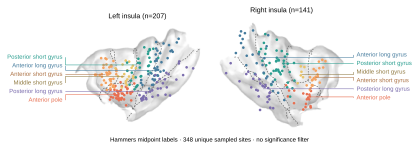

PosixPath('/cwork/ns458/insula-paper/img/supplementary/task_sampling/supp_hammers_insula_sampling.svg')

In [13]:
from src.supplementary.insula_spatial import prepare_spatial_tables,GYRI
spatial_sites,gyrus_counts,stage_hga,spatial_report=prepare_spatial_tables(ROOT,DATA_DIR)
display(gyrus_counts)
print(json.dumps(spatial_report,indent=2))
spatial_pixels=spatial_sites.merge(pixel_table.rename(columns={'channel':'site_id'}),on='site_id',validate='one_to_one')
from matplotlib import colors as mcolors

def draw_sampling_background(ax,hemi):
    image,overlay=backgrounds[hemi]
    ax.imshow(image);ax.set_xlim(0,image.shape[1]);ax.set_ylim(image.shape[0],0);ax.axis('off')
    for line in overlay.get('lines_minor',[]):
        ax.plot(line[:,0],line[:,1],linestyle=(0,(2.4,1.8)),color='0.40',lw=.65,zorder=5)

def _leader_ink(hex_color):
    rgb=np.array(mcolors.to_rgb(hex_color))
    luminance=0.2126*rgb[0]+0.7152*rgb[1]+0.0722*rgb[2]
    if luminance>0.62:
        rgb=rgb*(0.48/luminance)
    return mcolors.to_hex(np.clip(rgb,0,1))

def _cluster_tip(points,hemi):
    """Inside the cloud, in from the label-facing rim so the leader meets this gyrus."""
    xs=points.pixel_x.to_numpy(); ys=points.pixel_y.to_numpy()
    med_x=float(np.median(xs)); med_y=float(np.median(ys))
    deviation=np.abs(ys-med_y)
    band=deviation<=max(18.0,float(np.percentile(deviation,35)))
    if int(band.sum())<2:
        band=np.ones(len(xs),dtype=bool)
    if hemi=='lh':
        index=int(np.argmin(np.where(band,xs,np.inf)))
    else:
        index=int(np.argmax(np.where(band,xs,-np.inf)))
    rim_x,rim_y=float(xs[index]),float(ys[index])
    return rim_x+0.72*(med_x-rim_x), rim_y+0.72*(med_y-rim_y)

def _spread_label_ys(ys,lo,hi,gap):
    ys=np.asarray(ys,dtype=float)
    order=np.argsort(ys,kind='mergesort')
    placed=ys[order].copy()
    for _ in range(len(placed)*4):
        for i in range(1,len(placed)):
            slack=placed[i]-placed[i-1]-gap
            if slack<0:
                placed[i-1]+=slack/2
                placed[i]-=slack/2
        if placed[0]<lo:
            placed+=lo-placed[0]
        if placed[-1]>hi:
            placed-=placed[-1]-hi
    for i in range(1,len(placed)):
        placed[i]=max(placed[i],placed[i-1]+gap)
    if placed[-1]>hi:
        placed-=placed[-1]-hi
        for i in range(len(placed)-2,-1,-1):
            placed[i]=min(placed[i],placed[i+1]-gap)
    if placed[0]<lo or placed[-1]>hi or np.any(np.diff(placed)<gap-1e-6):
        placed=np.linspace(lo,hi,len(placed))
    out=np.empty_like(ys)
    out[order]=placed
    return out

def add_subdivision_leaders(fig,panels):
    """Full gyrus names beside the right hemisphere, joined to each cluster by an elbow leader."""
    fig.canvas.draw()
    renderer=fig.canvas.get_renderer()
    inv=fig.transFigure.inverted()
    fig_w_pt=fig.get_figwidth()*72
    fig_h_pt=fig.get_figheight()*72
    gap_y=8.6/fig_h_pt
    pad_y=2.0/fig_h_pt
    gutter_dx=5.0/fig_w_pt
    text_gap=3.0/fig_w_pt
    for hemi,ax,frame in panels:
        if hemi!='rh':
            continue
        extent=ax.get_window_extent(renderer).transformed(inv)
        specs=[]
        for key,(name,color) in GYRI.items():
            points=frame.loc[frame.hammers_gyrus.eq(key)]
            anchor_x,anchor_y=_cluster_tip(points,hemi)
            anchor_fig=inv.transform(ax.transData.transform((anchor_x,anchor_y)))
            specs.append(dict(name=name,ink=_leader_ink(color),anchor_x=anchor_x,anchor_y=anchor_y,
                              anchor_fy=float(anchor_fig[1])))
        label_fy=_spread_label_ys([spec['anchor_fy'] for spec in specs],
                                  extent.y0+pad_y,extent.y1-pad_y,gap_y)
        data_inv=ax.transData.inverted()
        for spec,fy in zip(specs,label_fy):
            gutter_fx=extent.x1+gutter_dx
            text_fx=gutter_fx+text_gap
            ha='left'
            gutter_anchor=data_inv.transform(fig.transFigure.transform((gutter_fx,spec['anchor_fy'])))
            gutter_label=data_inv.transform(fig.transFigure.transform((gutter_fx,fy)))
            ax.add_line(Line2D(
                [spec['anchor_x'],gutter_anchor[0],gutter_label[0]],
                [spec['anchor_y'],gutter_anchor[1],gutter_label[1]],
                transform=ax.transData,color=spec['ink'],lw=0.55,
                solid_capstyle='butt',clip_on=False,zorder=6.4))
            text_xy=data_inv.transform(fig.transFigure.transform((text_fx,fy)))
            ax.text(text_xy[0],text_xy[1],spec['name'],ha=ha,va='center',fontsize=6,
                    color=spec['ink'],clip_on=False,zorder=7)

assert spatial_pixels.site_id.nunique()==len(spatial_pixels)==348
probe=plt.figure(figsize=(4,1)); probe.canvas.draw()
_fp=font_manager.FontProperties(family='Arial',size=6)
label_w=max(probe.canvas.get_renderer().get_text_width_height_descent(name,_fp,False)[0]
            for name,_color in GYRI.values())/probe.dpi+0.28*cm
plt.close(probe)
brain_w=4.73*cm
rh_shape=backgrounds['rh'][0].shape
brain_h=brain_w*(rh_shape[0]/rh_shape[1])
side_gap=0.15*cm
mid=0.36*cm
fig_w=side_gap+brain_w+mid+brain_w+side_gap+label_w
fig_h=brain_h+1.05*cm
fig=plt.figure(figsize=(fig_w,fig_h))
bottom=0.42*cm/fig_h
height=brain_h/fig_h
left0=side_gap/fig_w
brain_wf=brain_w/fig_w
mid_f=mid/fig_w
panels=[]
for hemi,x0 in (('lh',left0),('rh',left0+brain_wf+mid_f)):
    ax=fig.add_axes([x0,bottom,brain_wf,height])
    draw_sampling_background(ax,hemi)
    frame=spatial_pixels.loc[spatial_pixels.display_hemi.eq(hemi)]
    for key,(name,color) in GYRI.items():
        points=frame.loc[frame.hammers_gyrus.eq(key)]
        ax.scatter(points.pixel_x,points.pixel_y,s=7,c=color,edgecolors='none',zorder=6)
    ax.set_title(f'{"Left" if hemi=="lh" else "Right"} insula (n={len(frame)})',fontsize=7)
    panels.append((hemi,ax,frame))
fig.text(.5,.02,'Hammers midpoint labels · 348 unique sampled sites · no significance filter',ha='center',fontsize=6)
add_subdivision_leaders(fig,panels)
save(fig,'supp_hammers_insula_sampling.svg')


## Stage-mean high gamma: point size

Same frozen 231 sound-responsive electrode waveforms as Figure 1. Means
use the approved phase windows: Stimulus 0–0.6 s, Delay 0–1 s, Response
−0.5–1 s. Each electrode contributes one value; no subject-first averaging.

Point area shares 0–0.4 z (5–60 pt²) on every phase. Values above 0.4 are
drawn at 60 pt², and negative values at 5 pt². The legend marks 0, 0.2, and
0.4 in black. Point color is the original within-phase scale (0 to that
phase's P95) and the original phase hue. Gray points are sites outside the
231 waveform cohort.


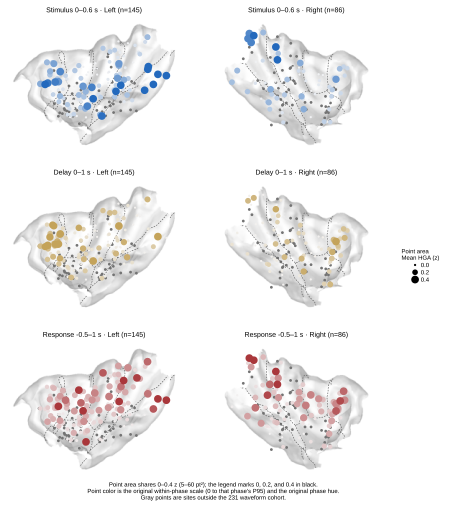

PosixPath('/cwork/ns458/insula-paper/img/supplementary/task_sampling/supp_stage_mean_hga_size.svg')

In [14]:
import seaborn as sns
from matplotlib.colors import Normalize
from matplotlib.lines import Line2D
from src.main_analysis import COMPONENT_COLORS, NMF_WINDOWS
STAGE_COMPONENT={'stimulus':'sensory','delay':'sustain','response':'motor'}
hga_pixels=stage_hga.merge(pixel_table.rename(columns={'channel':'site_id'}),on='site_id',validate='many_to_one')
fig=plt.figure(figsize=(16*cm,19*cm))
grid=fig.add_gridspec(3,2,left=.02,right=.90,top=.96,bottom=.11,wspace=.03,hspace=.22)

def point_area(values):
    return 5+np.clip(np.asarray(values,dtype=float)/0.4,0,1)*55

def legend_marker(area,color,label):
    return Line2D([],[],linestyle='',marker='o',markersize=float(np.sqrt(area)),
                  markerfacecolor=color,markeredgecolor='none',markeredgewidth=0,label=str(label))

for row,phase in enumerate(['stimulus','delay','response']):
    cmap=sns.light_palette(COMPONENT_COLORS[STAGE_COMPONENT[phase]],as_cmap=True)
    phase_data=hga_pixels.loc[hga_pixels.phase.eq(phase)]
    norm=Normalize(0,float(phase_data.display_p95.iloc[0]),clip=True)
    for col,hemi in enumerate(['lh','rh']):
        ax=fig.add_subplot(grid[row,col]);draw_sampling_background(ax,hemi)
        context=spatial_pixels.loc[spatial_pixels.display_hemi.eq(hemi)&~spatial_pixels.site_id.isin(phase_data.site_id)]
        ax.scatter(context.pixel_x,context.pixel_y,s=8,c='0.45',marker='o',edgecolors='none',linewidths=0,zorder=3)
        points=phase_data.loc[phase_data.display_hemi.eq(hemi)].sort_values('mean_hga')
        mean_hga=points.mean_hga.to_numpy()
        ax.scatter(points.pixel_x,points.pixel_y,s=point_area(mean_hga),
                   c=cmap(norm(mean_hga)),edgecolors='none',linewidths=0,zorder=6)
        lo,hi=NMF_WINDOWS[phase]
        ax.set_title(f'{phase.capitalize()} {lo:g}–{hi:g} s · {"Left" if hemi=="lh" else "Right"} (n={len(points)})',fontsize=7)
size_handles=[legend_marker(point_area(level),'black',f'{level:.1f}') for level in (0,0.2,0.4)]
fig.legend(handles=size_handles,title='Point area\nMean HGA (z)',frameon=False,fontsize=6,title_fontsize=6,
           loc='center left',bbox_to_anchor=(.91,.50),
           handlelength=1.1,handletextpad=.4,labelspacing=.3,borderaxespad=0)
fig.text(.5,.066,"Point area shares 0–0.4 z (5–60 pt²); the legend marks 0, 0.2, and 0.4 in black.\nPoint color is the original within-phase scale (0 to that phase's P95) and the original phase hue.\nGray points are sites outside the 231 waveform cohort.",ha='center',fontsize=6)
save(fig,'supp_stage_mean_hga_size.svg')


Same stage-mean map as one row of six panels: Stimulus, Delay, and Response, left then right.

lh on drawn insula: median 0.0px, max 2.0px, 1.000 within 4px (207 sites, 81 moved onto shown surface)
rh on drawn insula: median 0.0px, max 1.4px, 1.000 within 4px (141 sites, 50 moved onto shown surface)


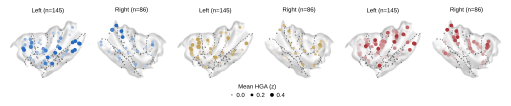

PosixPath('/cwork/ns458/insula-paper/img/supplementary/task_sampling/supp_stage_mean_hga_size_row_projected.svg')

In [15]:
# Projected companion of the 1x6 stage-mean row. Same panels, sites, titles,
# marker areas, phase colors, and gray context. Positions use Figure 2's
# full-pial snap. A vertex that is not on the insula surface shown in the
# panel is moved to the nearest drawn insula vertex that is.
import seaborn as sns
from matplotlib.colors import Normalize
from matplotlib.lines import Line2D
from scipy.ndimage import binary_dilation, distance_transform_edt
from scipy.spatial import cKDTree
from src.main_analysis import COMPONENT_COLORS
STAGE_COMPONENT={'stimulus':'sensory','delay':'sustain','response':'motor'}
TRACE_PHASES=['stimulus','delay','response']

def _snap_to_pial(coords, tree, pial):
    _, idx = tree.query(np.asarray(coords, dtype=float))
    idx = np.atleast_1d(np.asarray(idx, dtype=int))
    return np.asarray(pial, dtype=float)[idx], idx

def _shown_insula_vertices(hemi, image, project, camera):
    """Drawn insula vertices facing the camera and landing on the rendered mesh."""
    pial = np.asarray(lh_pial_coords if hemi == 'lh' else rh_pial_coords, dtype=float)
    surf = lh_surf if hemi == 'lh' else rh_surf
    drawn = np.unique(np.asarray(surf['faces'], dtype=np.int64))
    drawn_xyz = pial[drawn]
    normals = np.asarray(surf['normals'], dtype=float)[drawn]
    to_cam = np.asarray(camera, dtype=float).reshape(1, 3) - drawn_xyz
    to_cam /= np.clip(np.linalg.norm(to_cam, axis=1, keepdims=True), 1e-6, None)
    facing = np.einsum('ij,ij->i', normals, to_cam) > 0.0
    if int(facing.sum()) < 50:
        facing = np.ones(len(drawn), dtype=bool)
    candidates = drawn[facing]
    xy = project(pial[candidates])
    mask = binary_dilation(np.any(np.asarray(image) < 250, axis=2), iterations=2)
    h, w = mask.shape
    in_frame = (xy[:, 0] >= 0) & (xy[:, 0] < w) & (xy[:, 1] >= 0) & (xy[:, 1] < h)
    hits = np.zeros(len(candidates), dtype=bool)
    if in_frame.any():
        yy = np.rint(xy[in_frame, 1]).astype(int)
        xx = np.rint(xy[in_frame, 0]).astype(int)
        hits[in_frame] = mask[yy, xx]
    shown = candidates[hits] if int(hits.sum()) >= 50 else candidates
    return pial, shown

projected_panels = {}
fallback_counts = {}
for hemi in ['lh', 'rh']:
    image, project, brain = _render_insula_hemi(hemi, np.zeros((0, 3)), np.array([], dtype=object), np.array([]))
    overlay = overlay_continuous_gyrus_boundaries(hemi, project)
    pial, shown = _shown_insula_vertices(hemi, image, project, _camera_xyz(brain))
    shown_xyz = pial[shown]
    on_shown = np.zeros(len(pial), dtype=bool)
    on_shown[shown] = True
    side = reference.loc[reference.x.lt(0) if hemi == 'lh' else reference.x.gt(0)].reset_index(drop=True)
    coords = side[['x', 'y', 'z']].to_numpy()
    snapped, idx = _snap_to_pial(coords, cKDTree(pial), pial)
    off = ~on_shown[idx]
    n_off = int(off.sum())
    if n_off:
        _, near = cKDTree(shown_xyz).query(coords[off])
        snapped = snapped.copy()
        snapped[off] = shown_xyz[np.atleast_1d(np.asarray(near, dtype=int))]
    xy = project(snapped)
    brain.close()
    image, xy, overlay = _crop_panel(image, xy, overlay)
    side['pixel_x'] = xy[:, 0]
    side['pixel_y'] = xy[:, 1]
    side['display_hemi'] = hemi
    projected_panels[hemi] = (image, overlay, side)
    fallback_counts[hemi] = n_off

proj_pixels = pd.concat([projected_panels[hemi][2] for hemi in ['lh', 'rh']], ignore_index=True)
hga_projected = stage_hga.merge(
    proj_pixels.rename(columns={'channel': 'site_id'})[['site_id', 'pixel_x', 'pixel_y', 'display_hemi']],
    on='site_id', validate='many_to_one',
)
context_projected = proj_pixels.rename(columns={'channel': 'site_id'})
assert len(proj_pixels) == 348 and proj_pixels.channel.nunique() == 348
phase_counts = hga_projected.groupby('phase').site_id.nunique().reindex(TRACE_PHASES)
assert phase_counts.tolist() == [231, 231, 231], phase_counts.to_dict()

def _draw_projected_background(ax, hemi):
    image, overlay, _side = projected_panels[hemi]
    ax.imshow(image)
    ax.set_xlim(0, image.shape[1])
    ax.set_ylim(image.shape[0], 0)
    ax.axis('off')
    for line in overlay.get('lines_minor', []):
        ax.plot(line[:, 0], line[:, 1], linestyle=(0, (2.4, 1.8)), color='0.40', lw=.65, zorder=5)

def point_area(values):
    return 1.22 + np.clip(np.asarray(values, dtype=float) / 0.4, 0, 1) * 13.42

def legend_marker(area, color, label):
    return Line2D([], [], linestyle='', marker='o', markersize=float(np.sqrt(area)),
                  markerfacecolor=color, markeredgecolor='none', markeredgewidth=0, label=str(label))

for hemi in ['lh', 'rh']:
    image = projected_panels[hemi][0]
    dist = distance_transform_edt(~np.any(np.asarray(image) < 250, axis=2))
    frame = proj_pixels.loc[proj_pixels.display_hemi.eq(hemi)]
    h, w = dist.shape
    ys = np.clip(np.rint(frame.pixel_y.to_numpy()).astype(int), 0, h - 1)
    xs = np.clip(np.rint(frame.pixel_x.to_numpy()).astype(int), 0, w - 1)
    gaps = dist[ys, xs]
    print(f'{hemi} on drawn insula: median {np.median(gaps):.1f}px, max {gaps.max():.1f}px, '
          f'{(gaps <= 4).mean():.3f} within 4px ({len(frame)} sites, {fallback_counts[hemi]} moved onto shown surface)')
    if float((gaps > 8).mean()) > 0.02:
        raise RuntimeError(f'{hemi} projected markers are off the insula mesh')

fig_w_cm = 18
top_cm, brain_cm, legend_cm = 0.48, 2.25, 0.62
fig_h_cm = top_cm + brain_cm + legend_cm
fig = plt.figure(figsize=(fig_w_cm * cm, fig_h_cm * cm))
brain_top = 1 - top_cm / fig_h_cm
brain_bottom = brain_top - brain_cm / fig_h_cm
brain_outer = fig.add_gridspec(1, 1, left=.01, right=.99, top=brain_top, bottom=brain_bottom)
brain_grid = brain_outer[0].subgridspec(1, 6, wspace=.03)
col = 0
for phase in TRACE_PHASES:
    cmap = sns.light_palette(COMPONENT_COLORS[STAGE_COMPONENT[phase]], as_cmap=True)
    phase_data = hga_projected.loc[hga_projected.phase.eq(phase)]
    norm = Normalize(0, float(phase_data.display_p95.iloc[0]), clip=True)
    for hemi in ['lh', 'rh']:
        ax = fig.add_subplot(brain_grid[0, col])
        _draw_projected_background(ax, hemi)
        context = context_projected.loc[context_projected.display_hemi.eq(hemi) & ~context_projected.site_id.isin(phase_data.site_id)]
        ax.scatter(context.pixel_x, context.pixel_y, s=1.95, c='0.45', marker='o', edgecolors='none', linewidths=0, zorder=3)
        points = phase_data.loc[phase_data.display_hemi.eq(hemi)].sort_values('mean_hga')
        mean_hga = points.mean_hga.to_numpy()
        ax.scatter(points.pixel_x, points.pixel_y, s=point_area(mean_hga),
                   c=cmap(norm(mean_hga)), edgecolors='none', linewidths=0, zorder=6)
        ax.set_title(f'{"Left" if hemi == "lh" else "Right"} (n={len(points)})', fontsize=6)
        col += 1
size_handles = [legend_marker(point_area(level), 'black', f'{level:.1f}') for level in (0, 0.2, 0.4)]
fig.legend(handles=size_handles, ncol=3, frameon=False, fontsize=6, title='Mean HGA (z)', title_fontsize=6,
           loc='lower center', bbox_to_anchor=(0.5, 0.0),
           handlelength=.8, handletextpad=.35, columnspacing=.8, borderaxespad=0, borderpad=0.1)
save(fig, 'supp_stage_mean_hga_size_row_projected.svg')

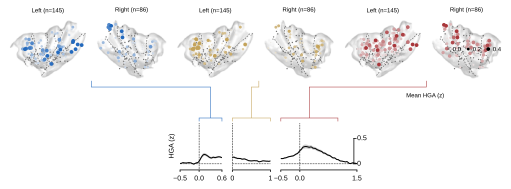

PosixPath('/cwork/ns458/insula-paper/img/supplementary/task_sampling/supp_stage_mean_hga_size_row.svg')

In [16]:
import seaborn as sns
from matplotlib.colors import Normalize
from matplotlib.lines import Line2D
from src.main_analysis import COMPONENT_COLORS, NMF_WINDOWS
STAGE_COMPONENT={'stimulus':'sensory','delay':'sustain','response':'motor'}
hga_pixels=stage_hga.merge(pixel_table.rename(columns={'channel':'site_id'}),on='site_id',validate='many_to_one')

# Frozen Figure 1 electrode-level group mean ± SEM. Read only; do not recompute waveforms.
trace_path=ROOT/'results/fig1/average_hga_group_trace.csv'
if not trace_path.is_file():
    raise FileNotFoundError(trace_path)
group_trace=pd.read_csv(trace_path)
missing_trace_cols={'phase','time','mean','std','count','sem'}-set(group_trace.columns)
if missing_trace_cols:
    raise ValueError(f'{trace_path} missing columns {sorted(missing_trace_cols)}')
TRACE_PHASES=['stimulus','delay','response']
# Same windows as frozen Figure 1 TRACE_XLIMS / FIG2_TRACE_XTICKS.
TRACE_XLIMS={'stimulus':(-.5,.6),'delay':(0.,1.),'response':(-.5,1.5)}
TRACE_XTICKS={'stimulus':(-.5,0,.6),'delay':(0,1),'response':(-.5,0,1.5)}
try:
    trace_label_size=fontsize
except NameError:
    trace_label_size=7
trace_width_ratios=[hi-lo for lo,hi in (TRACE_XLIMS[phase] for phase in TRACE_PHASES)]

# Brains stay full width at 2.25 cm. Traces sit in a centered 8 cm × 3 cm block
# using Figure 1's margins, so the axes match fig1_insula_average_traces.svg.
# Figure height is the top margin, brain row, connector gap, that 3 cm block,
# and the existing 1.50 cm caption strip. The size legend sits on the right of that gap.
fig_w_cm=18
trace_w_cm,trace_h_cm=8,3
top_cm,brain_cm,gap_cm,caption_cm=0.48,2.25,0.94,1.50
fig_h_cm=top_cm+brain_cm+gap_cm+trace_h_cm+caption_cm
fig=plt.figure(figsize=(fig_w_cm*cm,fig_h_cm*cm))
brain_top=1-top_cm/fig_h_cm
brain_bottom=brain_top-brain_cm/fig_h_cm
brain_outer=fig.add_gridspec(1,1,left=.01,right=.99,top=brain_top,bottom=brain_bottom)
brain_grid=brain_outer[0].subgridspec(1,6,wspace=.03)
trace_left=(fig_w_cm-trace_w_cm)/2/fig_w_cm
trace_width=trace_w_cm/fig_w_cm
trace_bottom_frac=caption_cm/fig_h_cm
trace_height=trace_h_cm/fig_h_cm
trace_grid=fig.add_gridspec(
    1,3,
    left=trace_left+0.16*trace_width,
    right=trace_left+0.94*trace_width,
    bottom=trace_bottom_frac+0.28*trace_height,
    top=trace_bottom_frac+0.82*trace_height,
    wspace=0.2,
    width_ratios=trace_width_ratios,
)

def point_area(values):
    return 1.22+np.clip(np.asarray(values,dtype=float)/0.4,0,1)*13.42

def legend_marker(area,color,label):
    return Line2D([],[],linestyle='',marker='o',markersize=float(np.sqrt(area)),
                  markerfacecolor=color,markeredgecolor='none',markeredgewidth=0,label=str(label))

brain_axes=[]
col=0
for phase in TRACE_PHASES:
    cmap=sns.light_palette(COMPONENT_COLORS[STAGE_COMPONENT[phase]],as_cmap=True)
    phase_data=hga_pixels.loc[hga_pixels.phase.eq(phase)]
    norm=Normalize(0,float(phase_data.display_p95.iloc[0]),clip=True)
    for hemi in ['lh','rh']:
        ax=fig.add_subplot(brain_grid[0,col]);draw_sampling_background(ax,hemi)
        brain_axes.append(ax)
        context=spatial_pixels.loc[spatial_pixels.display_hemi.eq(hemi)&~spatial_pixels.site_id.isin(phase_data.site_id)]
        ax.scatter(context.pixel_x,context.pixel_y,s=1.95,c='0.45',marker='o',edgecolors='none',linewidths=0,zorder=3)
        points=phase_data.loc[phase_data.display_hemi.eq(hemi)].sort_values('mean_hga')
        mean_hga=points.mean_hga.to_numpy()
        ax.scatter(points.pixel_x,points.pixel_y,s=point_area(mean_hga),
                   c=cmap(norm(mean_hga)),edgecolors='none',linewidths=0,zorder=6)
        lo,hi=NMF_WINDOWS[phase]
        ax.set_title(f'{"Left" if hemi=="lh" else "Right"} (n={len(points)})',fontsize=6)
        col+=1

trace_axes=[]
for col,phase in enumerate(TRACE_PHASES):
    lo,hi=TRACE_XLIMS[phase]
    phase_df=group_trace.loc[(group_trace.phase==phase)&(group_trace.time>=lo)&(group_trace.time<=hi)].sort_values('time')
    if phase_df.empty:
        raise ValueError(f'No saved rows for {phase} within {lo}–{hi} s in {trace_path}')
    ax=fig.add_subplot(trace_grid[0,col])
    ax.plot(phase_df.time,phase_df['mean'],color='k',lw=1)
    ax.fill_between(phase_df.time,phase_df['mean']-phase_df['sem'],
                    phase_df['mean']+phase_df['sem'],color='k',alpha=.2,linewidth=0)
    ax.set_xlim(lo,hi)
    ax.set_xticks(TRACE_XTICKS[phase])
    ax.set_xlabel('')
    trace_axes.append(ax)
for ax in trace_axes:
    ax.axvline(x=0,color='k',linestyle='--',linewidth=0.5,clip_on=False)
    ax.axhline(y=0,color='k',linestyle='--',linewidth=0.5,clip_on=False)
    ax.tick_params(labelsize=trace_label_size,width=0.75,length=2,which='both')
    plt.setp(ax.spines.values(),linewidth=0.75)
    sns.despine(ax=ax,offset=1,trim=True)
    ax.set_yticklabels([])
    ax.set_yticks([])
    ax.spines['left'].set_visible(False)
    ax.set_ylim(-0.1,0.8)
    ax.set_ylabel('HGA (z)' if ax is trace_axes[0] else '',fontsize=trace_label_size)
scale=0.5
ax=trace_axes[-1]
xmin,xmax=ax.get_xlim()
x_span=xmax-xmin
x_bar=xmax-0.04*x_span
cap=0.03*x_span
ax.plot([x_bar,x_bar],[0.0,scale],color='k',lw=0.75,clip_on=False)
ax.plot([x_bar,x_bar+cap],[0.0,0.0],color='k',lw=0.75,clip_on=False)
ax.plot([x_bar,x_bar+cap],[scale,scale],color='k',lw=0.75,clip_on=False)
ax.text(x_bar+1.4*cap,0.0,'0',fontsize=trace_label_size,va='center',ha='left')
ax.text(x_bar+1.4*cap,scale,'0.5',fontsize=trace_label_size,va='center',ha='left')

# One thin polyline per phase, in figure coordinates. Anchors come from the
# drawn axes: equal-aspect brains do not fill the gridspec cells. The stem
# starts in the Left/Right gap, drops to an elbow, and runs to the midpoint of
# NMF_WINDOWS[phase]. The bracket at that height spans lo–hi on the trace axis.
fig.canvas.draw()
renderer=fig.canvas.get_renderer()
to_figure=fig.transFigure.inverted()
drop_cm,title_clear_cm,tick_cm=0.22,0.06,0.12

def figure_x(ax,t):
    left,right=ax.get_xlim()
    t=min(max(float(t),left),right)
    return float(to_figure.transform(ax.transData.transform((t,0.0)))[0])

elbow_ys=[]
phase_links=[]
for index,phase in enumerate(TRACE_PHASES):
    ax=trace_axes[index]
    left=brain_axes[2*index].get_position()
    right=brain_axes[2*index+1].get_position()
    x_brain=0.5*(left.x1+right.x0)
    y_brain=0.5*(left.y0+right.y0)
    lo,hi=NMF_WINDOWS[phase]
    x_lo=figure_x(ax,lo)
    x_hi=figure_x(ax,hi)
    x_mid=figure_x(ax,(lo+hi)/2.0)
    axes_top=ax.get_position().y1
    # Tick bottoms keep the 0.06 cm clearance above the axes, so the bar sits one tick higher.
    y_bracket=axes_top+(title_clear_cm+tick_cm)/fig_h_cm
    y_tick=y_bracket-tick_cm/fig_h_cm
    y_elbow=y_brain-drop_cm/fig_h_cm
    elbow_ys.append(y_elbow)
    color=COMPONENT_COLORS[STAGE_COMPONENT[phase]]
    stem=Line2D(
        [x_brain,x_brain,x_mid,x_mid],
        [y_brain,y_elbow,y_elbow,y_bracket],
        transform=fig.transFigure,clip_on=False,
        color=color,linewidth=0.6,linestyle='-',solid_joinstyle='miter',solid_capstyle='butt',
        alpha=0.9,zorder=2,marker=None,
    )
    bracket=Line2D(
        [x_lo,x_lo,x_hi,x_hi],
        [y_tick,y_bracket,y_bracket,y_tick],
        transform=fig.transFigure,clip_on=False,
        color=color,linewidth=0.6,linestyle='-',solid_joinstyle='miter',solid_capstyle='butt',
        alpha=0.9,zorder=2,marker=None,
    )
    fig.add_artist(stem)
    fig.add_artist(bracket)
    phase_links.append(dict(stem=stem,bracket=bracket,x_lo=x_lo,x_hi=x_hi,
                            y_bracket=y_bracket,y_tick=y_tick,axes_top=axes_top))
trace_block_top=trace_bottom_frac+trace_height
row_right=brain_axes[-1].get_position().x1
size_handles=[legend_marker(point_area(level),'black',f'{level:.1f}') for level in (0,0.2,0.4)]
size_legend=fig.legend(handles=size_handles,ncol=3,frameon=False,fontsize=6,
           loc='center right',bbox_to_anchor=(row_right,0.5),
           handlelength=.8,handletextpad=.35,columnspacing=.8,borderaxespad=0,borderpad=0.1)
fig.canvas.draw()
legend_box=size_legend.get_window_extent(renderer).transformed(to_figure)
legend_y=min(elbow_ys)-0.20/fig_h_cm-legend_box.height/2
size_legend.set_bbox_to_anchor((row_right,legend_y))
fig.canvas.draw()
legend_box=size_legend.get_window_extent(renderer).transformed(to_figure)
hga_label=fig.text(legend_box.x0-0.10/fig_w_cm,legend_y,'Mean HGA (z)',ha='right',va='center',fontsize=6)
fig.canvas.draw()
label_box=hga_label.get_window_extent(renderer).transformed(to_figure)
legend_box=size_legend.get_window_extent(renderer).transformed(to_figure)
legend_extent=(min(legend_box.x0,label_box.x0),max(legend_box.x1,label_box.x1),
               min(legend_box.y0,label_box.y0),max(legend_box.y1,label_box.y1))

def bracket_hits_legend(link):
    x0,x1=sorted((link['x_lo'],link['x_hi']))
    y0,y1=link['y_tick'],link['y_bracket']
    # Top bar, plus the two downward end ticks.
    segments=[(x0,y0,x0,y1),(x0,y1,x1,y1),(x1,y1,x1,y0)]
    for xa,ya,xb,yb in segments:
        if xa==xb:
            if legend_extent[0]<=xa<=legend_extent[1] and ya<=legend_extent[3] and legend_extent[2]<=yb:
                return True
        elif ya==yb:
            if legend_extent[2]<=ya<=legend_extent[3] and xa<=legend_extent[1] and legend_extent[0]<=xb:
                return True
    return False

if any(bracket_hits_legend(link) for link in phase_links):
    pad=title_clear_cm/fig_h_cm
    for link in phase_links:
        if not bracket_hits_legend(link):
            continue
        y_bracket=min(link['y_bracket'],legend_extent[2]-pad)
        y_tick=y_bracket-tick_cm/fig_h_cm
        if y_tick<link['axes_top']:
            y_tick=link['axes_top']
            y_bracket=y_tick+tick_cm/fig_h_cm
        link['y_bracket']=y_bracket
        link['y_tick']=y_tick
        link['bracket'].set_data([link['x_lo'],link['x_lo'],link['x_hi'],link['x_hi']],
                                 [y_tick,y_bracket,y_bracket,y_tick])
        xs,ys=link['stem'].get_data()
        link['stem'].set_data(list(xs),[ys[0],ys[1],ys[2],y_bracket])
    fig.canvas.draw()
    legend_box=size_legend.get_window_extent(renderer).transformed(to_figure)
    label_box=hga_label.get_window_extent(renderer).transformed(to_figure)
    legend_extent=(min(legend_box.x0,label_box.x0),max(legend_box.x1,label_box.x1),
                   min(legend_box.y0,label_box.y0),max(legend_box.y1,label_box.y1))
    if any(bracket_hits_legend(link) for link in phase_links):
        bracket_top=max(link['y_bracket'] for link in phase_links if bracket_hits_legend(link))
        shift=(bracket_top+pad)-legend_extent[2]
        room=(min(elbow_ys)-pad)-legend_extent[3]
        shift=min(max(shift,0.0),max(room,0.0))
        if shift>0:
            legend_y=legend_y+shift
            size_legend.set_bbox_to_anchor((row_right,legend_y))
            hga_label.set_position((hga_label.get_position()[0],legend_y))
save(fig,'supp_stage_mean_hga_size_row.svg')

In [17]:
from datetime import datetime,timezone
inputs=[COHORT_DIR/'sampled_sites_by_subject_task.csv',COHORT_DIR/'sampled_sites_unique.csv',
        COHORT_DIR/'task_summary.csv',ROOT/'results/fig1/insula_plot_coordinates.csv']
manifest=dict(condition=CONDITION,modality=MODALITY,cohort_version='sound_only_2026-10-17',
              unique_sampled_sites=348,unique_confirmed_responsive_sites=231,
              subject_task_counts=len(subject_counts),task_site_records=len(sample),
              inputs={str(p):hashlib.sha256(p.read_bytes()).hexdigest() for p in inputs},
              figures=[str(p) for p in sorted(IMG_DIR.glob('*.svg'))],
              caption_note='Frozen Figure 1 cohort; incomplete sound-response evidence is not negative. This is not a new post-restoration QC cohort.',
              completed_utc=datetime.now(timezone.utc).isoformat())
(DATA_DIR/'figure_manifest.json').write_text(json.dumps(manifest,indent=2)+'\n')
display(pd.DataFrame([manifest]).drop(columns=['inputs','figures']))


,condition,modality,cohort_version,unique_sampled_sites,unique_confirmed_responsive_sites,subject_task_counts,task_site_records,caption_note,completed_utc
0,Repeat,sound,sound_only_2026-10-17,348,231,260,605,Frozen Figure 1 cohort; incomplete sound-respo...,2026-10-21T00:42:33.434720+00:00
